In [ ]:
import pandas as pd 
import numpy as np
import mwtab
import sys,os
sys.path.append(os.path.abspath("/users/j/a/jaileru/metabolomics-toolkit/"))
from dimensionality_reduction import *
import seaborn as sns
import plotly.io as pio

pio.renderers.default = "iframe"

%load_ext gofigr
from gofigr.jupyter import *

configure(analysis=FindByName("ST002118-EDA-06142026", create=True), 
          auto_publish=True)

In [ ]:
untargeted_data = pd.read_parquet("../data/reference_copy_untargeted_data.parquet")
categorical_data = pd.read_parquet("../data/reference_copy_categorical_data.parquet")
annotations = pd.read_excel("../info/Rough annotations_in house and public databases_HHEAR Lichtveld, 5-9-24.xlsx",sheet_name='In-House Matching Data',header=3)

In [ ]:
trimester_1 = untargeted_data.loc[categorical_data[categorical_data['Trimester_n'] == 1].index,:]
trimester_3 = untargeted_data.loc[categorical_data[categorical_data['Trimester_n'] == 3].index,:]

In [ ]:
annotations = annotations[['Query Signal Name','Ontology Level']]
OL_1 = list(set(annotations[annotations['Ontology Level'] == "OL_1"]['Query Signal Name']))

In [ ]:
import re
def to_mz_rt(name):
    m = re.match(r'^(?:[A-Za-z]+_)?(\d+)_(\d+)_(\d+)_(\d+)(m[_/]z|n)$', name)
    if not m:
        return name  # leave anything that doesn't match unchanged
    rt = f'{m.group(1)}.{m.group(2)}'
    mz = f'{m.group(3)}.{m.group(4)}'
    suffix = 'm/z' if m.group(5).startswith('m') else 'n'
    return f'{rt}_{mz}{suffix}'
rename_map = {c: to_mz_rt(c) for c in untargeted_data.columns if c.startswith("K")}

trimester_1 = trimester_1.rename(columns=rename_map).copy()
trimester_3 = trimester_3.rename(columns=rename_map).copy()

trimester_1_OL_1 = trimester_1.loc[:,trimester_1.columns.isin(OL_1)]
trimester_3_OL_1 = trimester_3.loc[:,trimester_3.columns.isin(OL_1)]

In [109]:
categorical_data[categorical_data['v108a'] == 6]

,OriginalSubjectID,v107,v107d,v107e,v107f,v107g,v107h,v107k,v107m,v107n,...,Jeff_ID,Jeff_ID_b,SUBJECT_SAMPLE_FACTORS,HHEAR_ID,Rawfilename,HHEAR_ID_a,Jeff_ID_a,HHEAR_ID_c,PrimaryLast,Trimester_n
Lab_ID,,,,,,,,,,,,,,,,,,,,,
Lich_S_122,P20365,20.873374,2.0,2.0,1.0,2.0,2.0,1.0,1.0,1.0,...,H-2GST4-S-00,H-2GST4-S-00,SUBJECT_SAMPLE_FACTORS,Lich_S_122,RAW_FILE_NAME=Lich_S_122,Lich_S_122,H-2GST4-S-00,Lich_S_122,1.0,3.0
Lich_S_619,P20365,20.873374,2.0,2.0,1.0,2.0,2.0,1.0,1.0,1.0,...,H-2H8B9-S-00,H-2H8B9-S-00,SUBJECT_SAMPLE_FACTORS,Lich_S_619,RAW_FILE_NAME=Lich_S_619,Lich_S_619,H-2H8B9-S-00,Lich_S_619,1.0,1.0


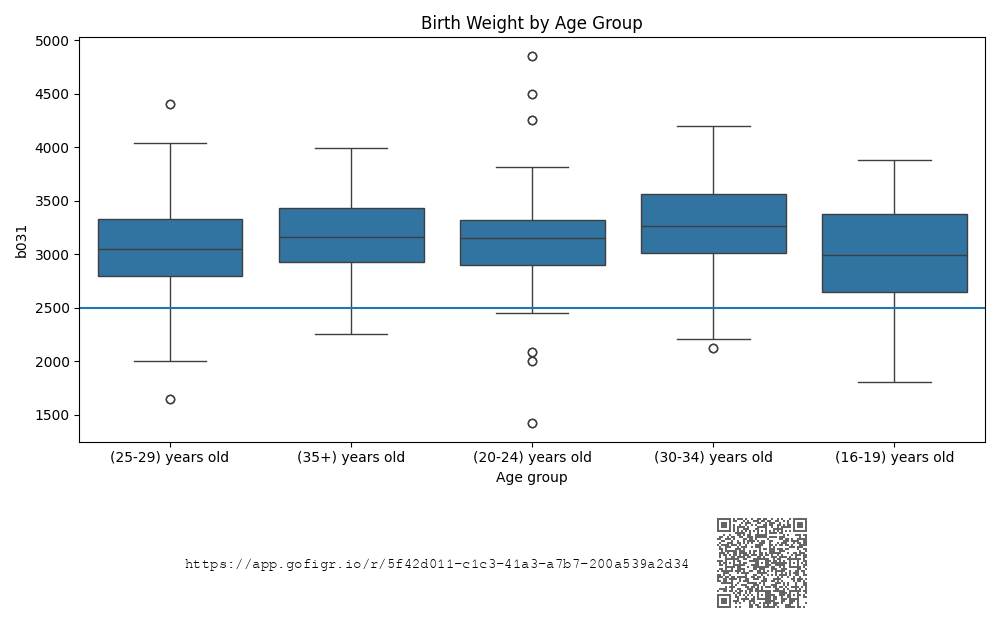


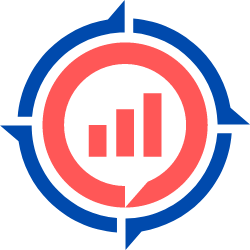
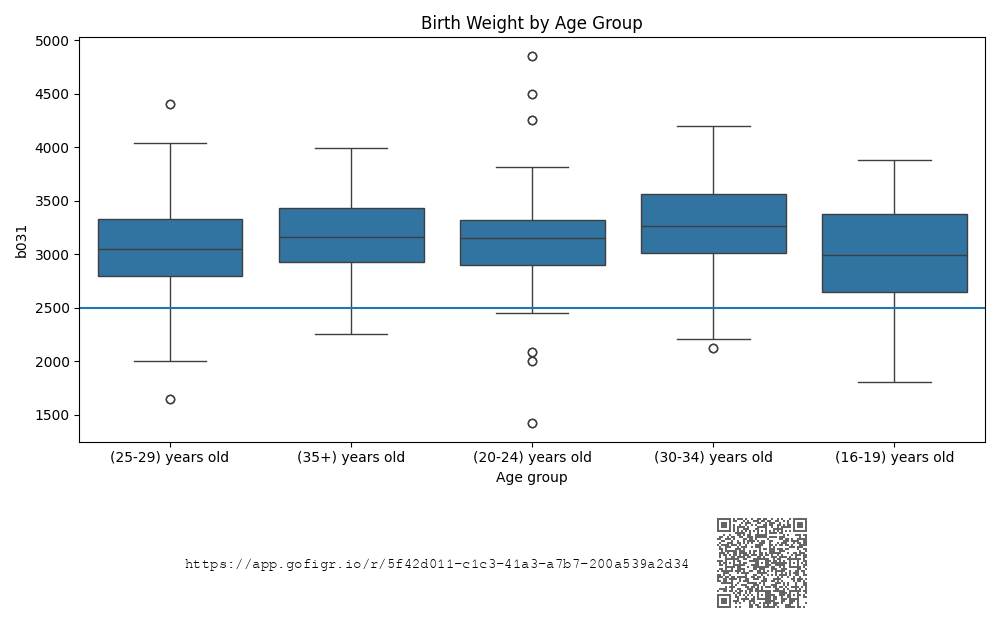
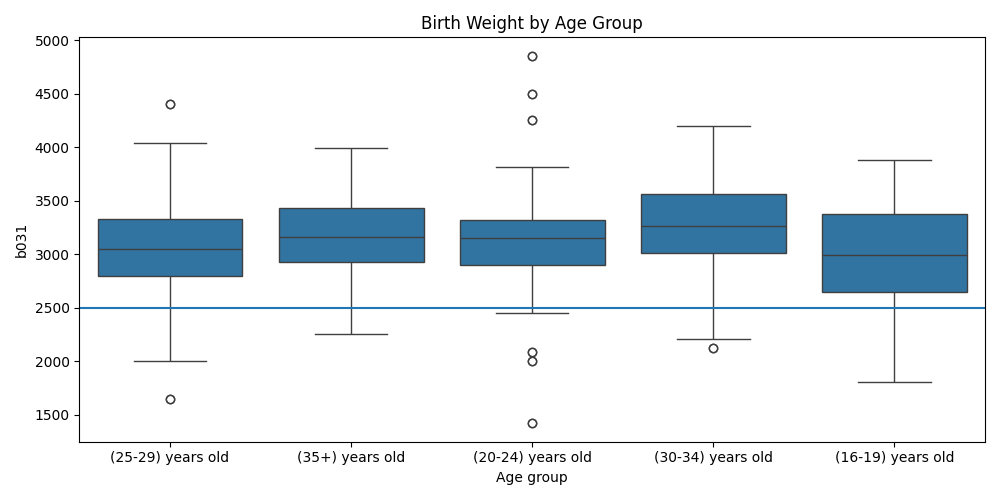
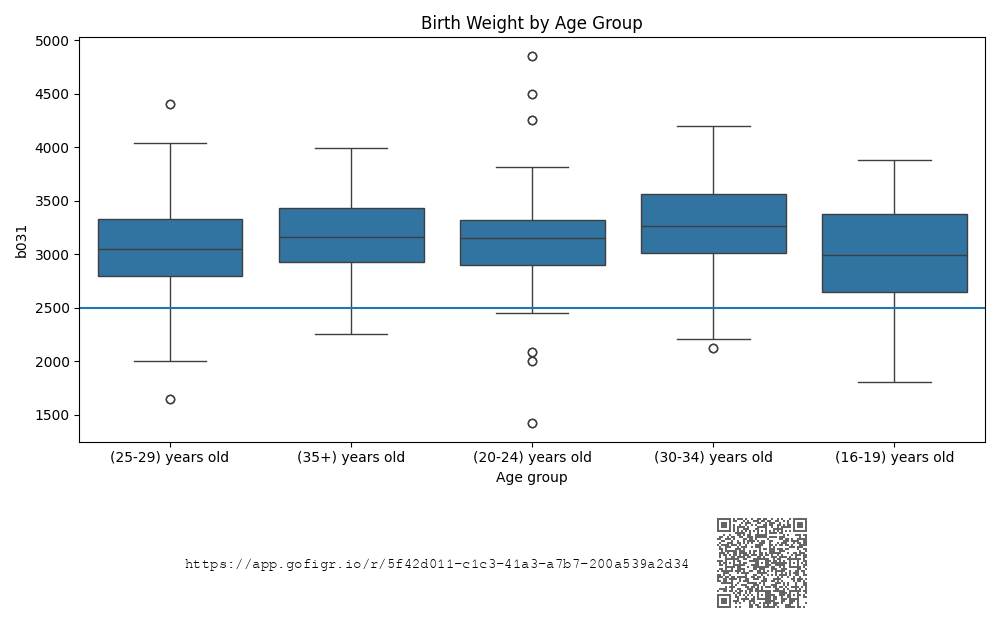
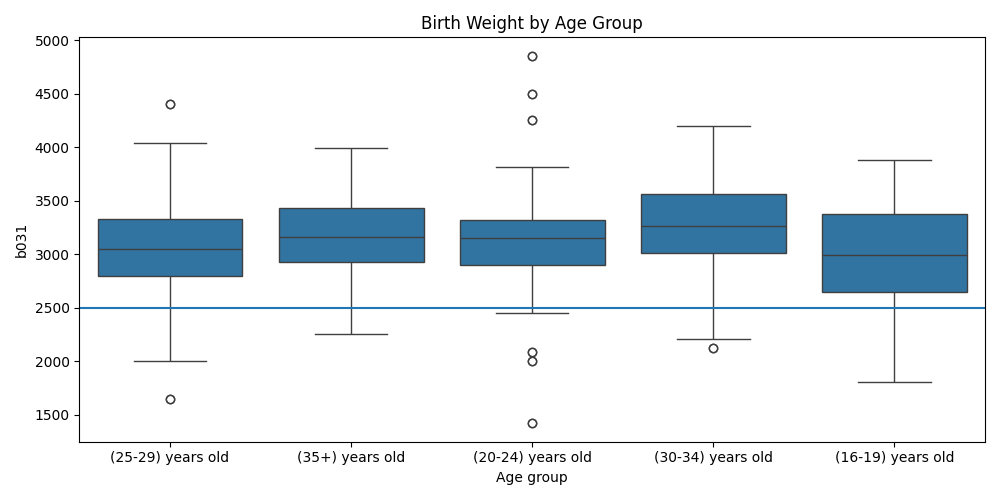

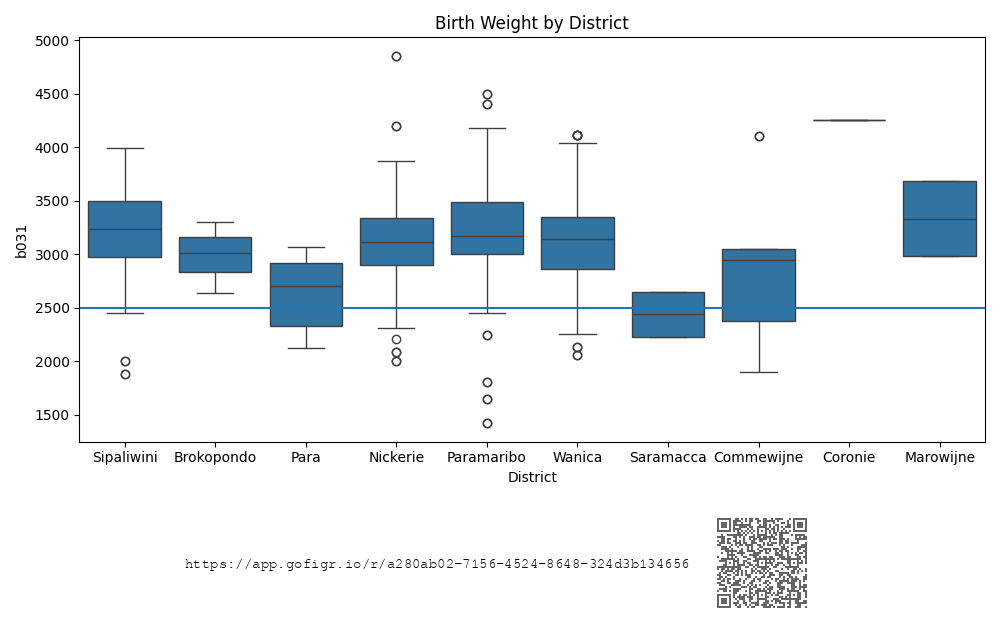


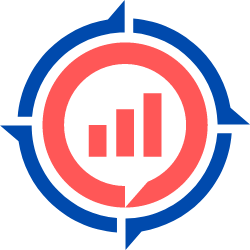
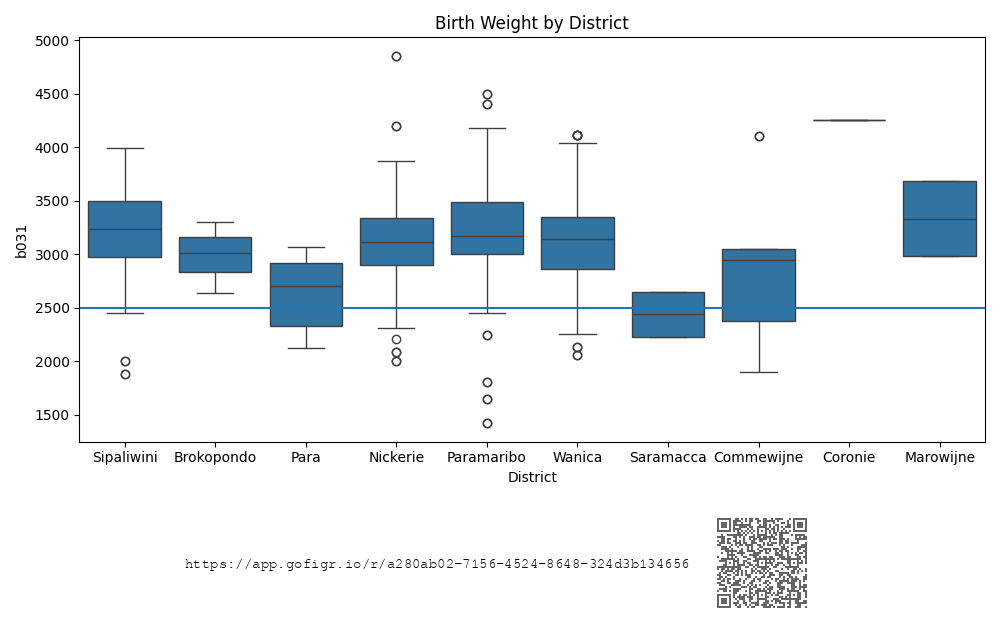
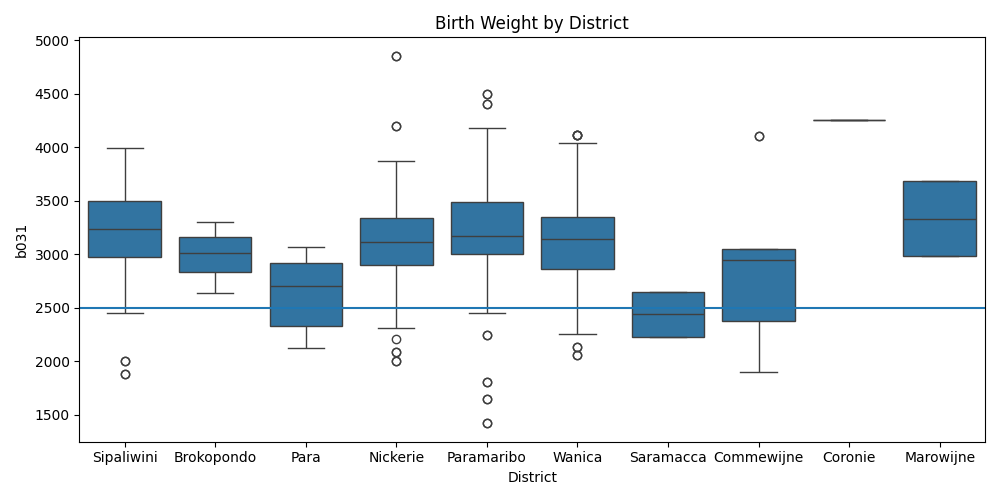
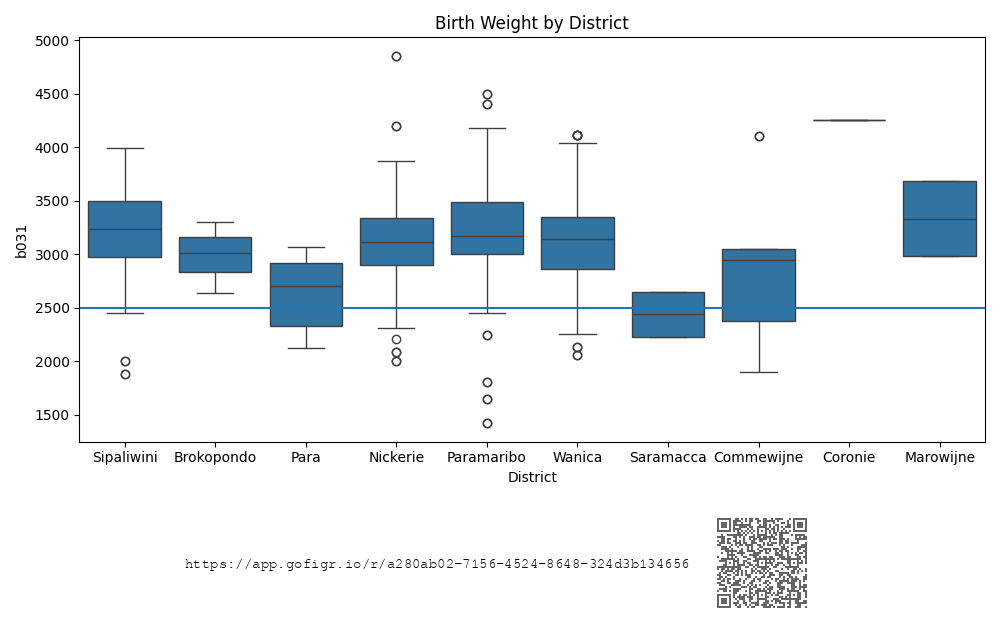
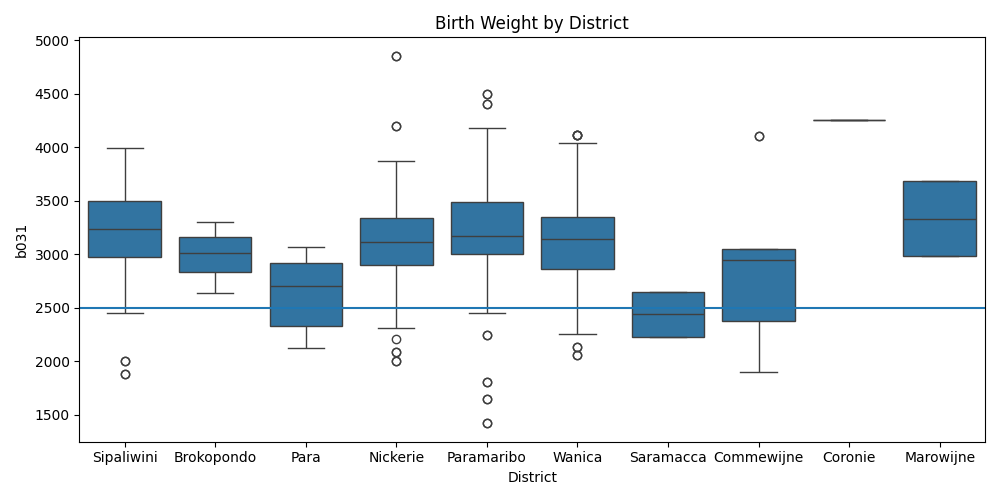

In [96]:
group = categorical_data[['b031', 'v107e','v108a']].copy()

age_map = {
    "1.0": "(16-19) years old",
    "2.0": "(20-24) years old",
    "3.0": "(25-29) years old",
    "4.0": "(30-34) years old",
    "5.0": "(35+) years old"
}
district_map = {"1.0":"Paramaribo",
                "2.0": "Wanica",
                "3.0": "Commewijne",
                "4.0": "Marowijne",
                "5.0": "Saramacca",
                "6.0" : "Coronie",
                "7.0": "Nickerie",
                "8.0": "Para",
                "9.0": "Brokopondo",
                "10.0": "Sipaliwini"
}
group['v108a'] = group['v108a'].astype(str).map(district_map)
group['v107e'] = group['v107e'].astype(str).map(age_map)

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(
    data=group,          # <-- was categorical_data
    x='v107e',
    y='b031',
    ax=ax
)
ax.set_xlabel('Age group')
ax.set_ylabel('b031')
ax.set_title('Birth Weight by Age Group')
ax.axhline(2500)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(
    data=group,          # <-- was categorical_data
    x='v108a',
    y='b031',
    ax=ax
)
ax.set_xlabel('District')
ax.set_ylabel('b031')
ax.axhline(2500)
ax.set_title('Birth Weight by District')
plt.tight_layout()
plt.show()

## Color by Prenatal Information
 - v107e
 - v107f
 - v107
 - v108a

Dropping sample 'Lich_S_603': missing value for hue='v108a'
Dropping sample 'Lich_S_310': missing value for hue='v108a'


,PC1,PC2,v108a
Lab_ID,,,
Lich_S_390,-41.310092,-33.428315,10.0
Lich_S_395,-31.877654,-59.860743,10.0
Lich_S_269,-0.404040,-16.766368,10.0
Lich_S_387,-7.787725,-20.124999,10.0
Lich_S_369,-15.074331,-11.674811,10.0
...,...,...,...
Lich_S_405,-27.721587,33.711388,1.0
Lich_S_135,-36.661653,41.548130,8.0
Lich_S_360,-21.586982,-9.131820,2.0


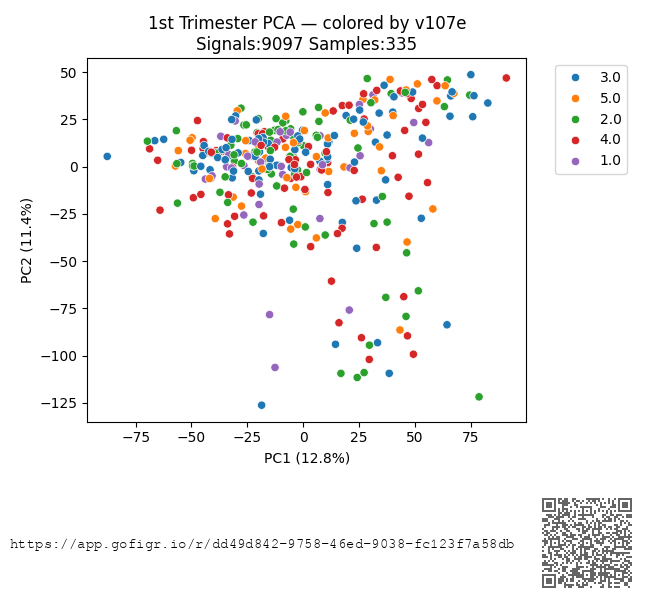


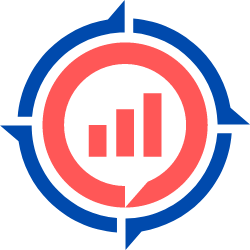
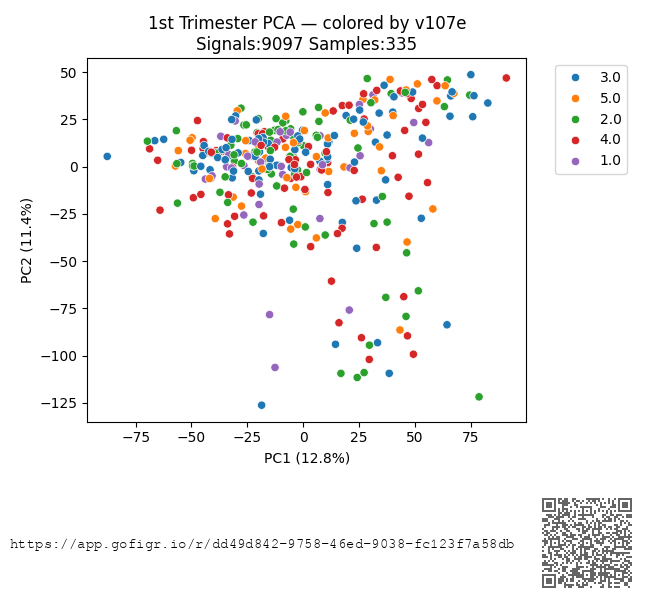
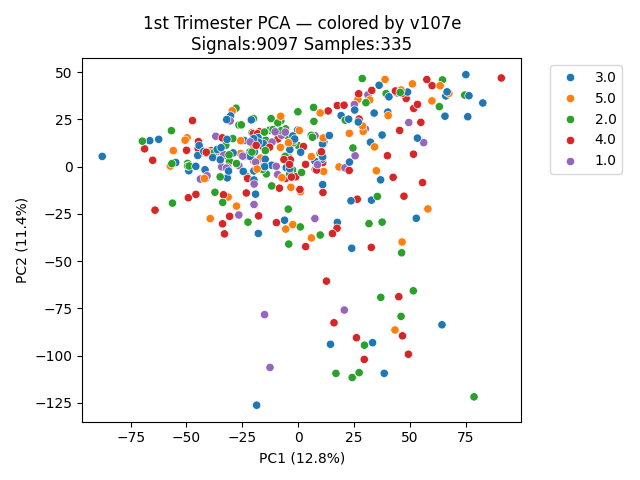
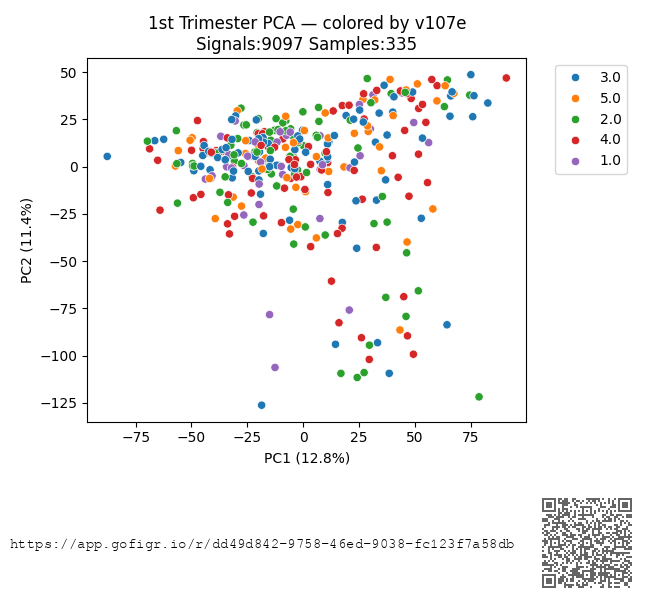
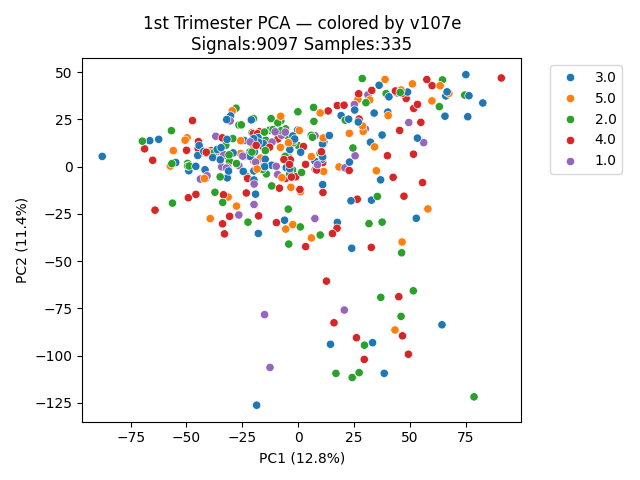

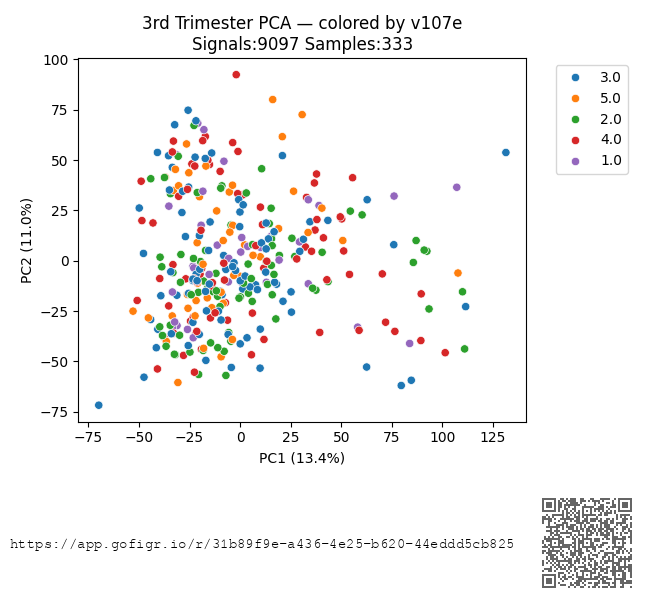


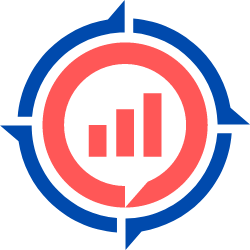
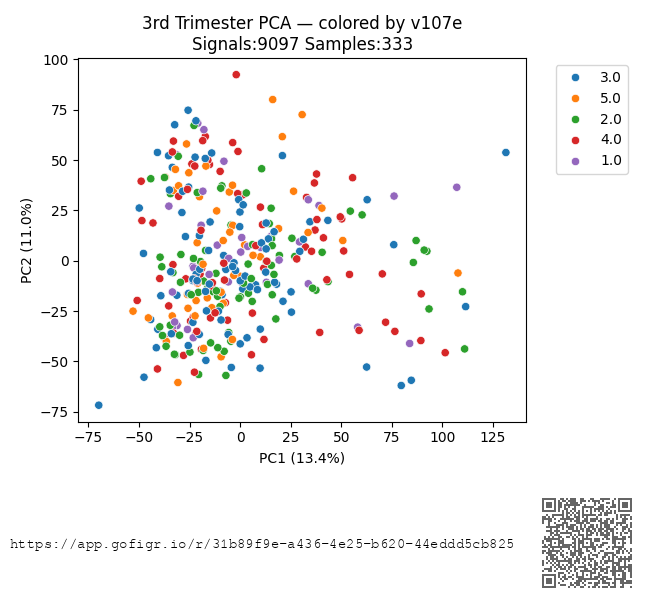
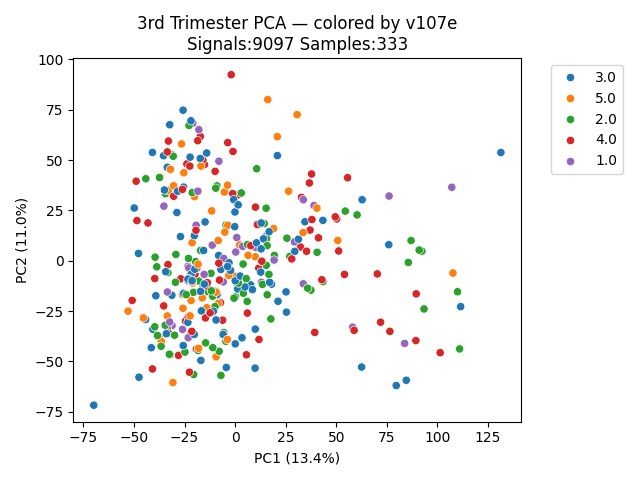
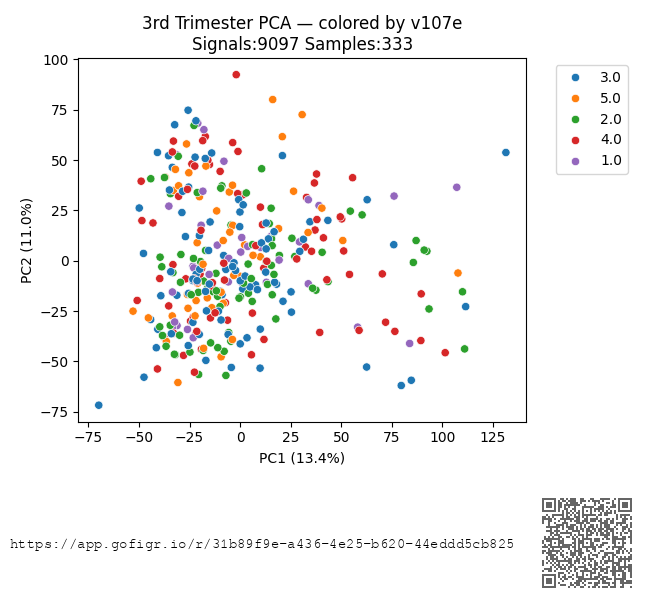
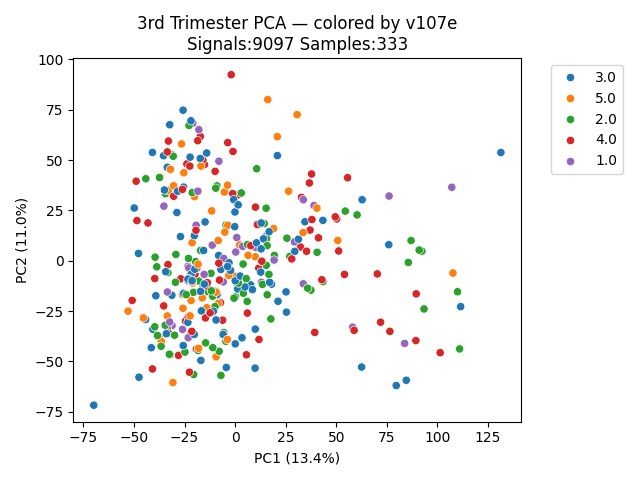

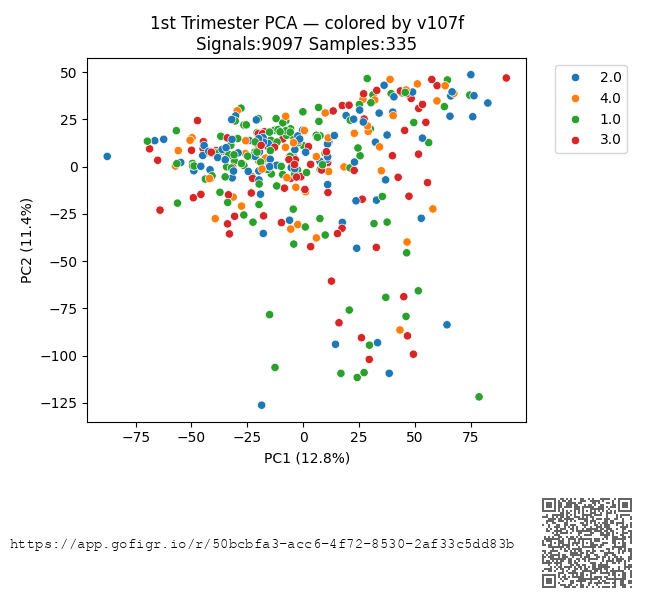


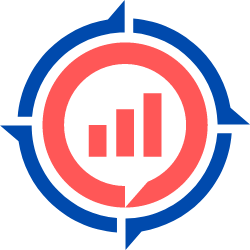
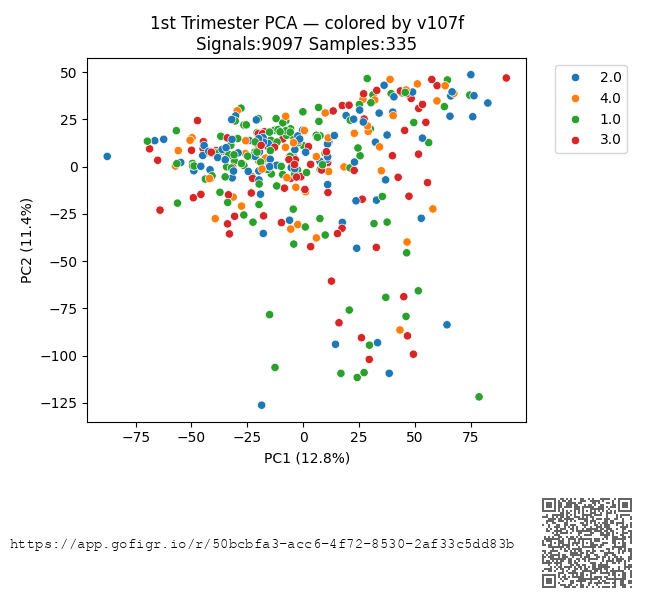
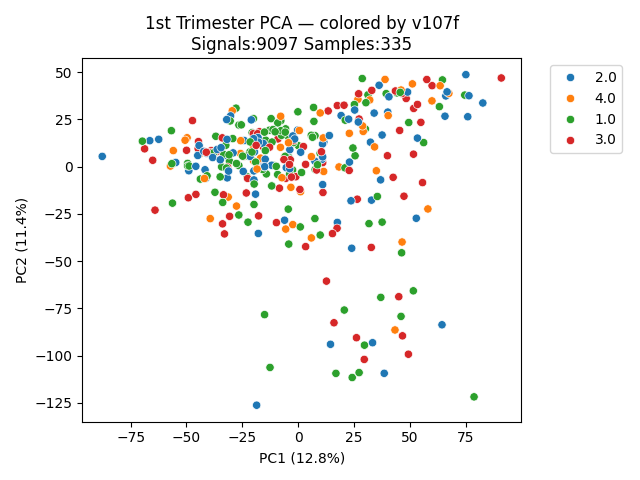
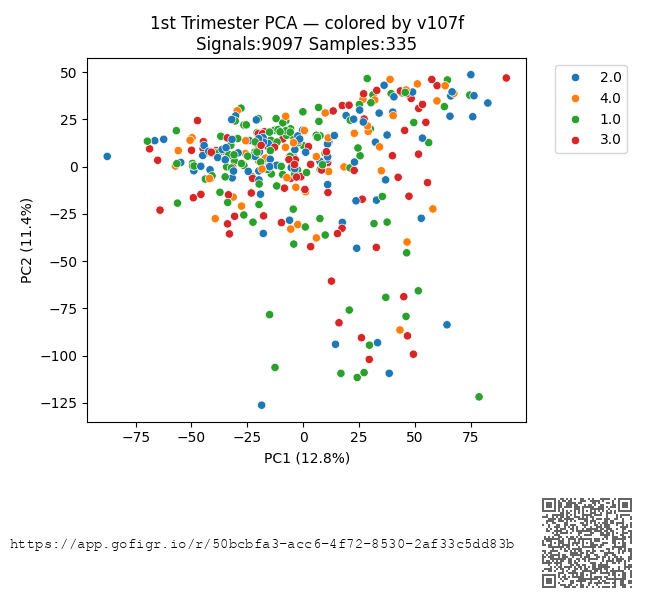
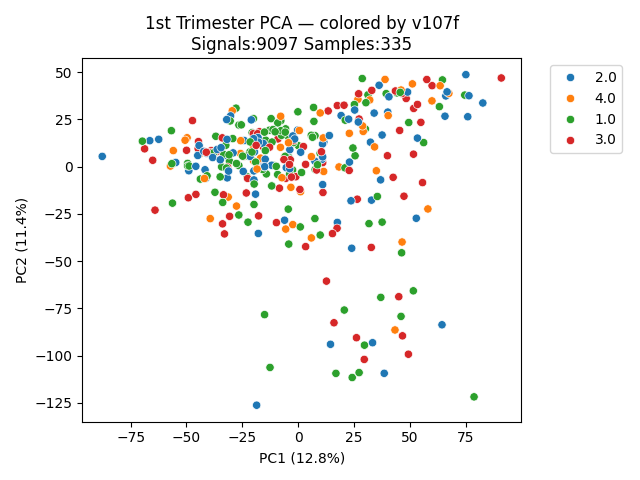

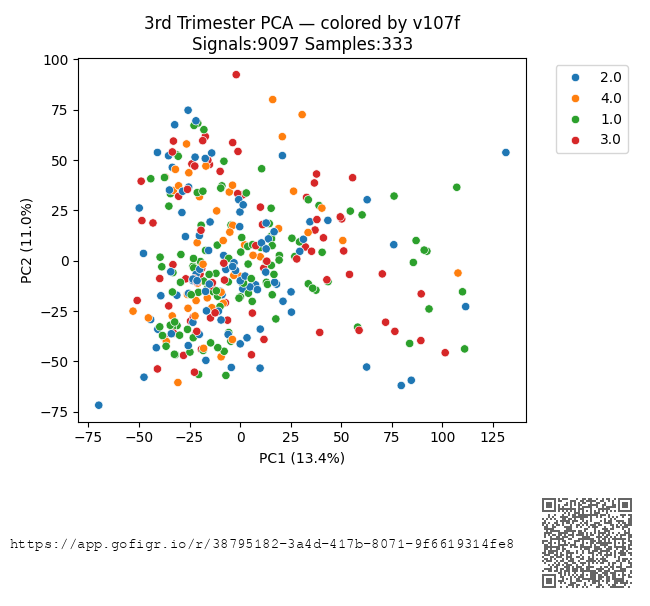


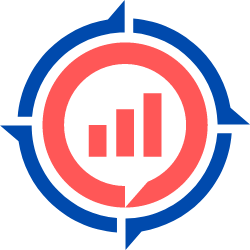
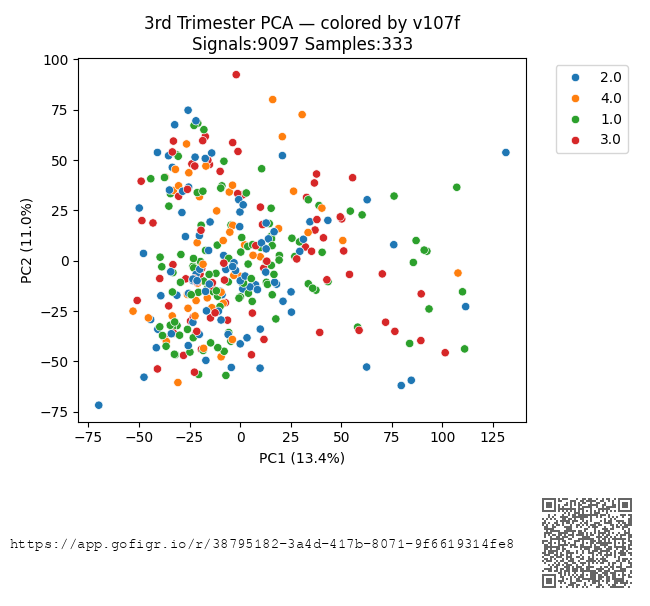
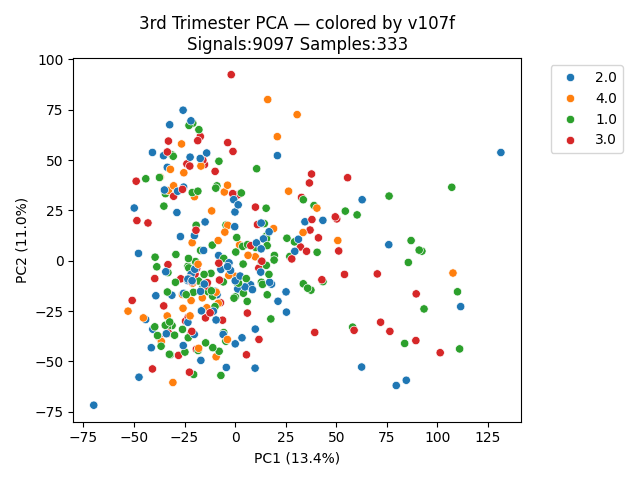
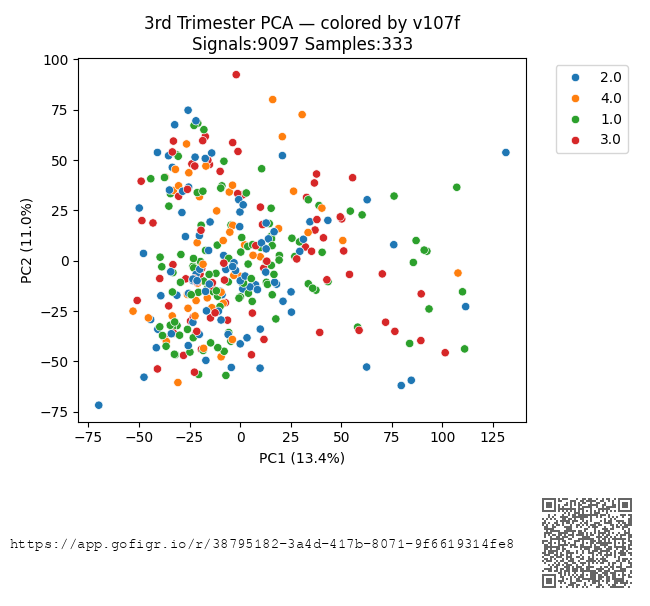
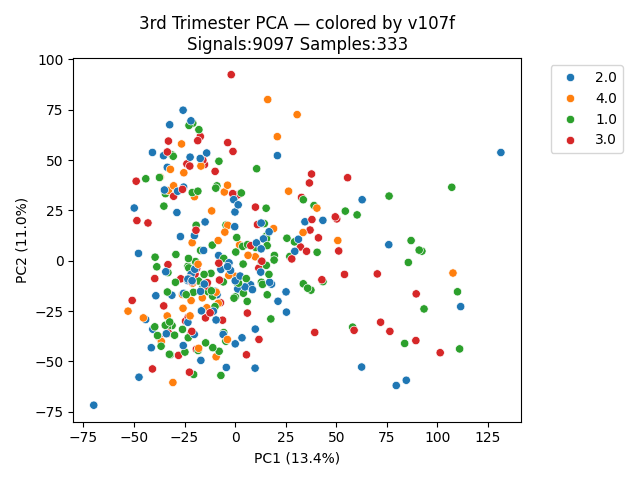

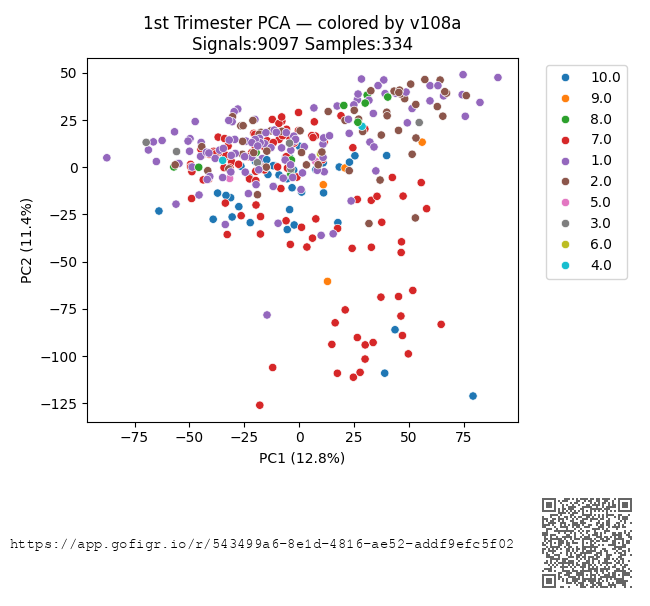


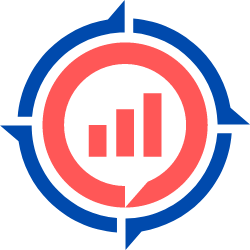
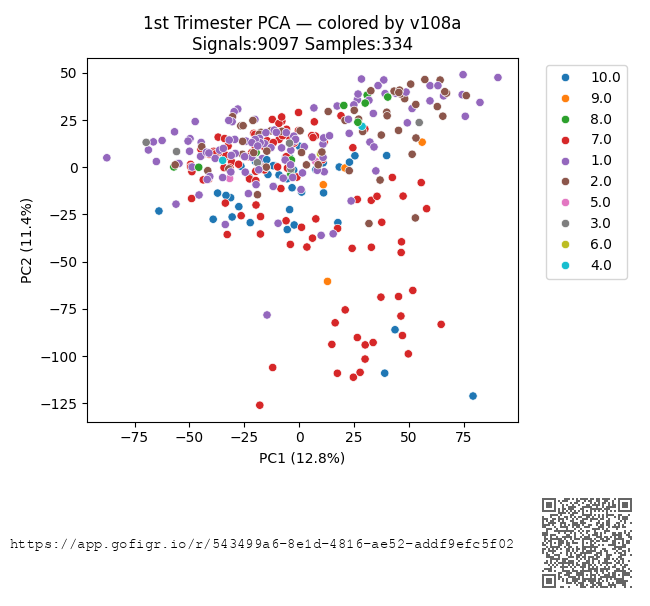
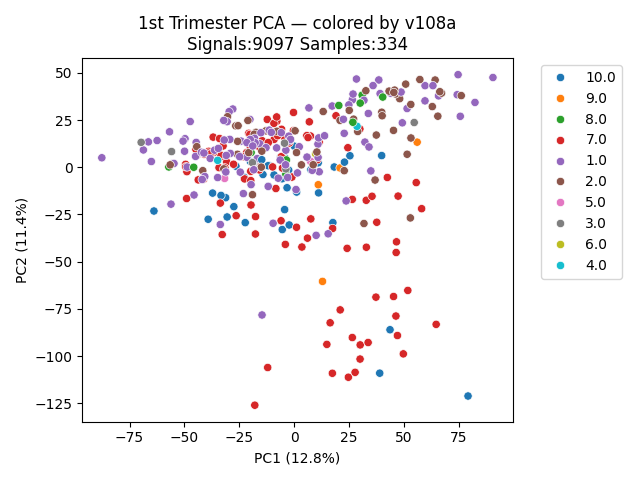
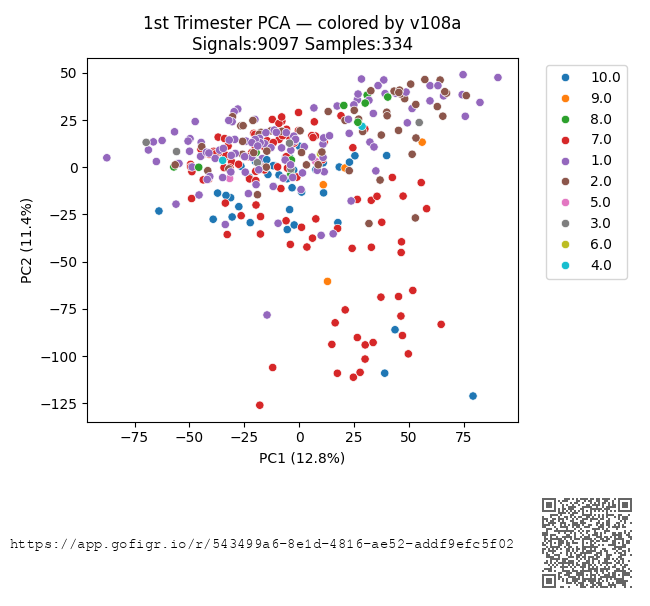
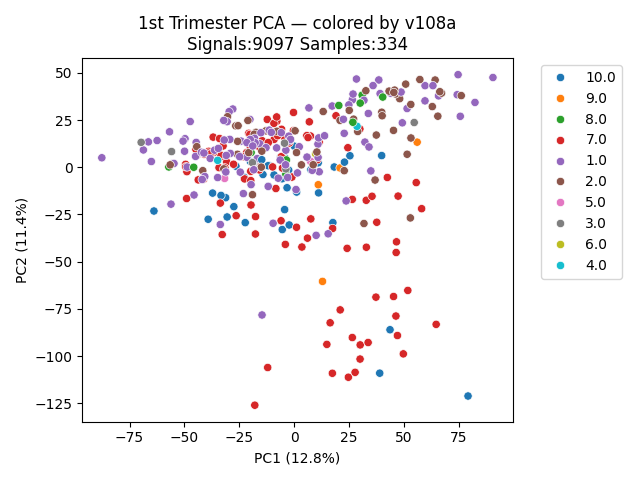

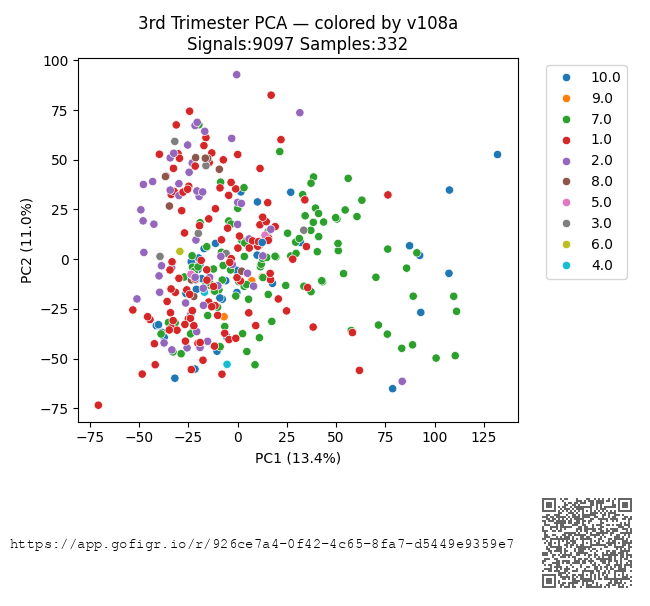


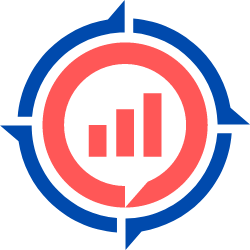
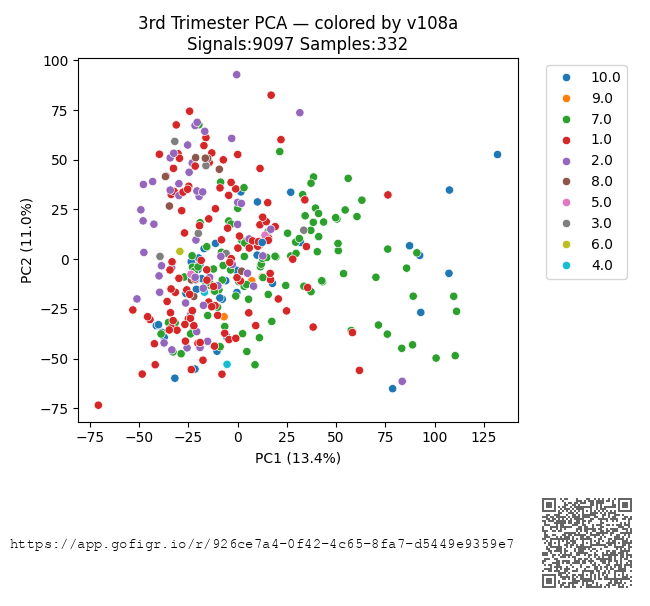
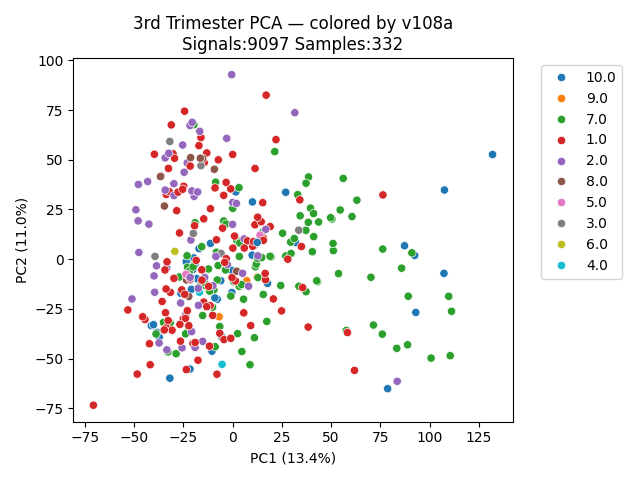
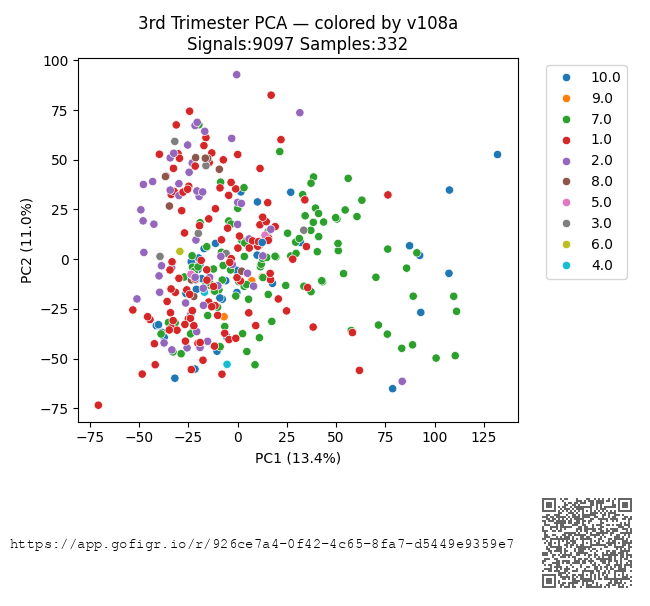
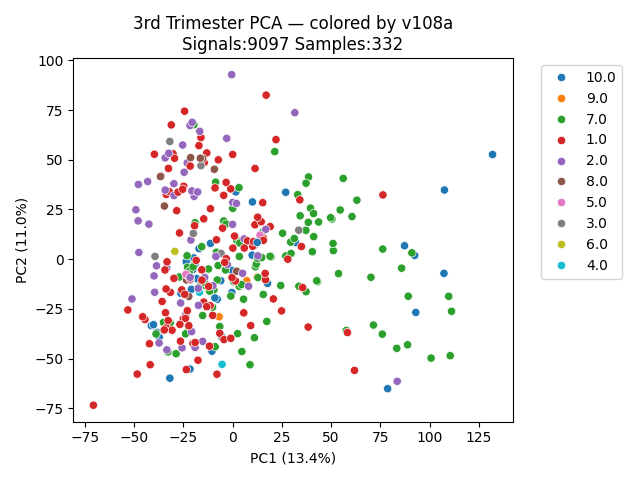

In [52]:
pca_plot(trimester_1,categorical_data,hue=['v107e'],title='1st Trimester PCA')
pca_plot(trimester_3,categorical_data,hue=['v107e'],title='3rd Trimester PCA')

pca_plot(trimester_1,categorical_data,hue=['v107f'],title='1st Trimester PCA')
pca_plot(trimester_3,categorical_data,hue=['v107f'],title='3rd Trimester PCA')


pca_plot(trimester_1,categorical_data,hue=['v108a'],title='1st Trimester PCA')
pca_plot(trimester_3,categorical_data,hue=['v108a'],title='3rd Trimester PCA')

In [ ]:
pca_plot(trimester_1_OL_1,categorical_data,hue=['v107e'],title='1st Trimester PCA -- OL_1 Only')
pca_plot(trimester_3_OL_1,categorical_data,hue=['v107e'],title='3rd Trimester PCA -- OL_1 Only')

pca_plot(trimester_1_OL_1,categorical_data,hue=['v107f'],title='1st Trimester PCA -- OL_1 Only')
pca_plot(trimester_3_OL_1,categorical_data,hue=['v107f'],title='3rd Trimester PCA -- OL_1 Only')


pca_plot(trimester_1_OL_1,categorical_data,hue=['v108a'],title='1st Trimester PCA -- OL_1 Only')
pca_plot(trimester_3_OL_1,categorical_data,hue=['v108a'],title='3rd Trimester PCA -- OL_1 Only')

## Using OL-1 Signals Only 

In [ ]:
trimester_1 = trimester_1.rename(columns=rename_map).copy()
trimester_3 = trimester_3.rename(columns=rename_map).copy()

trimester_1_OL_1 = trimester_1.loc[:,trimester_1.columns.isin(OL_1)]
trimester_3_OL_1 = trimester_3.loc[:,trimester_3.columns.isin(OL_1)]

In [ ]:
# Gender Baby
pca_plot(trimester_1_OL_1,categorical_data,hue=['b030a'],title='1st Trimester PCA -- OL-1 Signals Only')
pca_plot(trimester_3_OL_1,categorical_data,hue=['b030a'],title='3rd Trimester PCA -- OL-1 Signals Only')

In [ ]:
mod1=OPLSDA(trimester_1_OL_1,categorical_data,y_var='b030a',orthoI=1,predI=1)
plt.figure()
mod2=OPLSDA(trimester_3_OL_1,categorical_data,y_var='b030a',orthoI=1,predI=1)

In [ ]:
# Birthweight <2500 grams
pca_plot(trimester_1_OL_1,categorical_data,hue=['b031a'],title='1st Trimester PCA -- OL-1 Signals Only')
pca_plot(trimester_3_OL_1,categorical_data,hue=['b031a'],title='3rd Trimester PCA -- OL-1 Signals Only')

In [ ]:
mod3=OPLSDA(trimester_1_OL_1,categorical_data,y_var='b031a',orthoI=1,predI=1)
plt.figure()
mod4=OPLSDA(trimester_3_OL_1,categorical_data,y_var='b031a',orthoI=1,predI=1)

In [ ]:
# Preterm birth <37.0 weeks
pca_plot(trimester_1_OL_1,categorical_data,hue=['b034c'],title='1st Trimester PCA -- OL-1 Signals Only')
pca_plot(trimester_3_OL_1,categorical_data,hue=['b034c'],title='3rd Trimester PCA -- OL-1 Signals Only')

In [ ]:
mod5=OPLSDA(trimester_1_OL_1,categorical_data,y_var='b034c',orthoI=1,predI=1)
plt.figure()
mod6=OPLSDA(trimester_3_OL_1,categorical_data,y_var='b034c',orthoI=1,predI=1)

In [ ]:
# APGAR score at 5 min
pca_plot(trimester_1_OL_1,categorical_data,hue=['b035b'],title='1st Trimester PCA -- OL-1 Signals Only')
pca_plot(trimester_3_OL_1,categorical_data,hue=['b035b'],title='3rd Trimester PCA -- OL-1 Signals Only')

In [ ]:
# Adverse Birth Outcomes
pca_plot(trimester_1_OL_1,categorical_data,hue=['b040'],title='1st Trimester PCA -- OL-1 Signals Only')
pca_plot(trimester_3_OL_1,categorical_data,hue=['b040'],title='3rd Trimester PCA -- OL-1 Signals Only')

In [ ]:
mod7=OPLSDA(trimester_1_OL_1,categorical_data,y_var='b040',orthoI=1,predI=1)
plt.figure()
mod8=OPLSDA(trimester_3_OL_1,categorical_data,y_var='b040',orthoI=1,predI=1)

In [ ]:
# OL-1 Only All Data (PCA)
all_samples = pd.concat([trimester_1_OL_1,trimester_3_OL_1])
pca_plot(all_samples,categorical_data,hue=['b030a'],title='Both Trimester PCA -- OL-1 Signals Only')
pca_plot(all_samples,categorical_data,hue=['b031a'],title='Both Trimester PCA -- OL-1 Signals Only')
pca_plot(all_samples,categorical_data,hue=['b034c'],title='Both Trimester PCA -- OL-1 Signals Only')
pca_plot(all_samples,categorical_data,hue=['b035b'],title='Both Trimester PCA -- OL-1 Signals Only')
pca_plot(all_samples,categorical_data,hue=['b040'],title='Both Trimester PCA -- OL-1 Signals Only')

In [ ]:
# OL-1 Only All Data (OPLS-DA)
OPLSDA(all_samples,categorical_data,y_var='b030a',orthoI=1,predI=1)
plt.figure()
OPLSDA(all_samples,categorical_data,y_var='b031a',orthoI=1,predI=1)
plt.figure()
OPLSDA(all_samples,categorical_data,y_var='b034c',orthoI=1,predI=1)
plt.figure()
OPLSDA(all_samples,categorical_data,y_var='b040',orthoI=1,predI=1)
plt.figure()